<a href="https://colab.research.google.com/github/kansweldone/SRMMarks/blob/main/01_data_prep_lawbot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json, re, random, unicodedata, collections
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)

DATA_DIR = Path('/content')
OUT_DIR = Path('/content/outputs')
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(sorted(p.name for p in DATA_DIR.glob('*.json')))

['constitution_qa.json', 'crpc_qa.json', 'ipc_qa.json']


Step2

In [2]:
FILES = {'constitution_qa.json': 'Constitution', 'crpc_qa.json': 'CrPC', 'ipc_qa.json': 'IPC'}

records = []
for fname, src in FILES.items():
    data = json.load(open(DATA_DIR / fname, encoding='utf-8'))
    print(f'{fname:22s} {len(data):6d} records, keys: {sorted(collections.Counter(k for r in data for k in r))}')
    for r in data:
        records.append({'instruction': r.get('question') or r.get('instruction'),
                        'output': r.get('answer') or r.get('output'),
                        'source': src})
raw = pd.DataFrame(records)
print('\nMerged:', len(raw))
raw.groupby('source').size()

constitution_qa.json     4082 records, keys: ['answer', 'question']
crpc_qa.json             8194 records, keys: ['answer', 'id', 'question']
ipc_qa.json              2267 records, keys: ['answer', 'question']

Merged: 14543


,0
source,
Constitution,4082
CrPC,8194
IPC,2267


step3

In [3]:
TRANS = str.maketrans({'\u2018': "'", '\u2019': "'", '\u201c': '"', '\u201d': '"',
                       '\u2013': '-', '\u2014': '-', '\u2026': '...', '\u00a0': ' '})

def clean(s):
    if not isinstance(s, str):
        return ''
    s = unicodedata.normalize('NFKC', s).translate(TRANS)
    return re.sub(r'\s+', ' ', s).strip()

df = raw.copy()
df['instruction'] = df['instruction'].map(clean)
df['output'] = df['output'].map(clean)
empty = (df.instruction == '') | (df.output == '')
print('Empty rows dropped:', int(empty.sum()))
df = df[~empty].reset_index(drop=True)
print('Non-ASCII chars left:', sum(ord(c) > 127 for t in df.instruction + df.output for c in t))

Empty rows dropped: 0
Non-ASCII chars left: 0


step4

In [4]:
norm = lambda s: re.sub(r'[^a-z0-9]+', ' ', s.lower()).strip()
df['q_norm'], df['a_norm'] = df.instruction.map(norm), df.output.map(norm)

# 3a. same question + same answer (ignoring case/punctuation) -> keep one
n0 = len(df)
df = df.drop_duplicates(['source', 'q_norm', 'a_norm']).reset_index(drop=True)
n_pair_dups = n0 - len(df)

# 3b. same question, different answers -> keep the longest (most informative) answer
df['a_len'] = df.output.str.len()
n1 = len(df)
df = (df.sort_values('a_len', ascending=False, kind='stable')
        .drop_duplicates(['source', 'q_norm'])
        .sort_index().reset_index(drop=True))
n_conflicts = n1 - len(df)

print(f'Duplicate Q&A pairs removed : {n_pair_dups}')
print(f'Conflicting answers resolved: {n_conflicts}')
print(f'Remaining                   : {len(df)}')

Duplicate Q&A pairs removed : 22
Conflicting answers resolved: 52
Remaining                   : 14469


step5

In [5]:
SEC_RE = re.compile(r'(?<![-\w])(Section|Sec\.|Article|Art\.|Schedule|Chapter)\s+([0-9]+[A-Z]{0,2}|[IVXLC]+)\b', re.I)
CANON = {'sec.': 'Section', 'section': 'Section', 'art.': 'Article', 'article': 'Article',
         'schedule': 'Schedule', 'chapter': 'Chapter'}

def refs(text):
    out = []
    for kind, num in SEC_RE.findall(text):
        r = f'{CANON[kind.lower()]} {num.upper()}'
        if r not in out:
            out.append(r)
    return out

df['refs'] = (df.instruction + ' ' + df.output).map(refs)
df['has_ref'] = df.refs.str.len() > 0
print(df.groupby('source').has_ref.agg(['sum', 'mean']).rename(columns={'sum': 'rows_with_ref', 'mean': 'share'}))
df[df.has_ref][['source', 'instruction', 'output', 'refs']].head(5)

              rows_with_ref     share
source                               
Constitution            409  0.100838
CrPC                   2251  0.276129
IPC                     419  0.185316


,source,instruction,output,refs
18,Constitution,What does any law referred to in article 2 or ...,Such law contains provisions for the amendment...,"[Article 2, Article 3]"
19,Constitution,What do the provisions of a law referred to in...,These laws typically contain provisions for th...,"[Article 2, Article 3]"
20,Constitution,What is not considered an amendment of the Con...,Any law referred to in article 2 or article 3 ...,"[Article 2, Article 3, Article 368]"
21,Constitution,What is the status of any law referred to in a...,Any law referred to in article 2 or article 3 ...,"[Article 2, Article 3, Article 368]"
46,Constitution,What does article 14 of the Constitution of In...,Article 14 states that the State shall not den...,[Article 14]


step6

In [6]:
# --- union-find: each row starts in its own group; link() merges groups ---
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def link(idx):
    idx = list(idx)
    for j in idx[1:]:
        parent[find(j)] = find(idx[0])

# rule 1: same question (any source) -> same group
for idx in df.groupby('q_norm').indices.values():
    link(idx)
# rule 2: same long answer (>= 8 words) within a source -> same group
long_ans = df[df.a_norm.str.split().str.len() >= 8]
for idx in long_ans.groupby(['source', 'a_norm']).groups.values():    link(idx)

df['group'] = [find(i) for i in range(len(df))]
sizes = df.group.value_counts()
print(f'{len(df)} rows -> {len(sizes)} groups; multi-row groups: {(sizes > 1).sum()}, largest: {sizes.max()}')

# --- shuffle groups, fill train up to 80% per source, rest go to val ---
target = (0.8 * df.source.value_counts()).to_dict()
n_train = dict.fromkeys(target, 0)
split = {}
groups = df.groupby('group').source.agg(lambda s: s.value_counts().to_dict())
for g in groups.sample(frac=1, random_state=SEED).index:
    counts = groups[g]
    main = max(counts, key=counts.get)
    split[g] = 'train' if n_train[main] < target[main] else 'val'
    if split[g] == 'train':
        for s, n in counts.items():
            n_train[s] += n
df['split'] = df.group.map(split)

tab = pd.crosstab(df.source, df.split, margins=True)
tab['val_%'] = (100 * tab['val'] / tab['All']).round(1)
print(tab)
tr_q = set(df[df.split == 'train'].q_norm)
print('Validation questions that also appear in train:', int(df[df.split == 'val'].q_norm.isin(tr_q).sum()))

14469 rows -> 12733 groups; multi-row groups: 1391, largest: 75
split         train   val    All  val_%
source                                 
Constitution   3245   811   4056   20.0
CrPC           6522  1630   8152   20.0
IPC            1809   452   2261   20.0
All           11576  2893  14469   20.0
Validation questions that also appear in train: 0


step7

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(df.instruction)
tr, va = df[df.split == 'train'], df[df.split == 'val']
best = cosine_similarity(vec.transform(va.instruction), vec.transform(tr.instruction)).max(axis=1)
for t in (0.9, 0.8, 0.7):
    print(f'val questions with a train question at cosine >= {t}: {(best >= t).sum():4d} ({(best >= t).mean():.1%})')

val questions with a train question at cosine >= 0.9:   61 (2.1%)
val questions with a train question at cosine >= 0.8:  232 (8.0%)
val questions with a train question at cosine >= 0.7:  492 (17.0%)


step8

q_words                                           a_words        \
               count  mean   std  min   25%   50%   75%    max   count  mean   
source                                                                         
Constitution  4056.0  18.2  10.4  3.0  12.0  16.0  22.0  136.0  4056.0  24.7   
CrPC          8152.0  17.0   8.2  3.0  11.0  16.0  21.0  107.0  8152.0  18.5   
IPC           2261.0  17.9  10.0  3.0  11.0  16.0  22.0   96.0  2261.0  23.4   

                                                  
               std  min   25%   50%   75%    max  
source                                            
Constitution  22.4  1.0   9.0  19.0  34.0  235.0  
CrPC          16.3  1.0   7.0  14.0  26.0  145.0  
IPC           17.7  1.0  11.0  20.0  30.0  163.0

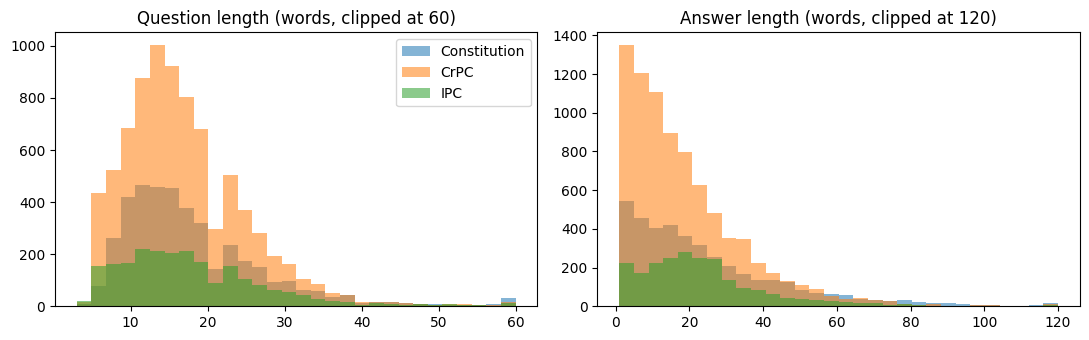

In [9]:
df['q_words'] = df.instruction.str.split().str.len()
df['a_words'] = df.output.str.split().str.len()
display(df.groupby('source')[['q_words', 'a_words']].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for src, sub in df.groupby('source'):
    ax[0].hist(sub.q_words.clip(upper=60), bins=30, alpha=.55, label=src)
    ax[1].hist(sub.a_words.clip(upper=120), bins=30, alpha=.55, label=src)
ax[0].set_title('Question length (words, clipped at 60)')
ax[1].set_title('Answer length (words, clipped at 120)')
ax[0].legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'phase1_length_hist.png', dpi=130)
plt.show()

step 9

In [10]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/LawBot
!cp /content/outputs/* /content/drive/MyDrive/LawBot/
!ls -la /content/drive/MyDrive/LawBot

Mounted at /content/drive
total 8813
drwx------ 2 root root    4096 Oct 11 04:48 .
drwx------ 8 root root    4096 Oct 11 04:48 ..
-rw------- 1 root root 4486857 Oct 11 04:48 lawbot_cleaned.jsonl
-rw------- 1 root root 3588252 Oct 11 04:48 lawbot_train.jsonl
-rw------- 1 root root  898605 Oct 11 04:48 lawbot_val.jsonl
-rw------- 1 root root   40916 Oct 11 04:48 phase1_length_hist.png
